In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


In [10]:
from analysis.allocation import kelly_fraction, expected_log_growth
from scipy.optimize import minimize_scalar
import numpy as np
import matplotlib.pyplot as plt

In [8]:
# Test kelly formula using optimizer

q, p = 0.6, 0.4
def neg_growth(f):
    return -expected_log_growth(q, p, f)

result = minimize_scalar(neg_growth, bounds=(1e-9, 1 - 1e-9), method="bounded")

numerical_optimum = result.x        
closed_form = kelly_fraction(q, p)  

print(f"numerical: {numerical_optimum:.6f}")
print(f"closed form: {closed_form:.6f}")
print(f"difference: {abs(numerical_optimum - closed_form):.2e}")

numerical: 0.333334
closed form: 0.333333
difference: 5.13e-07


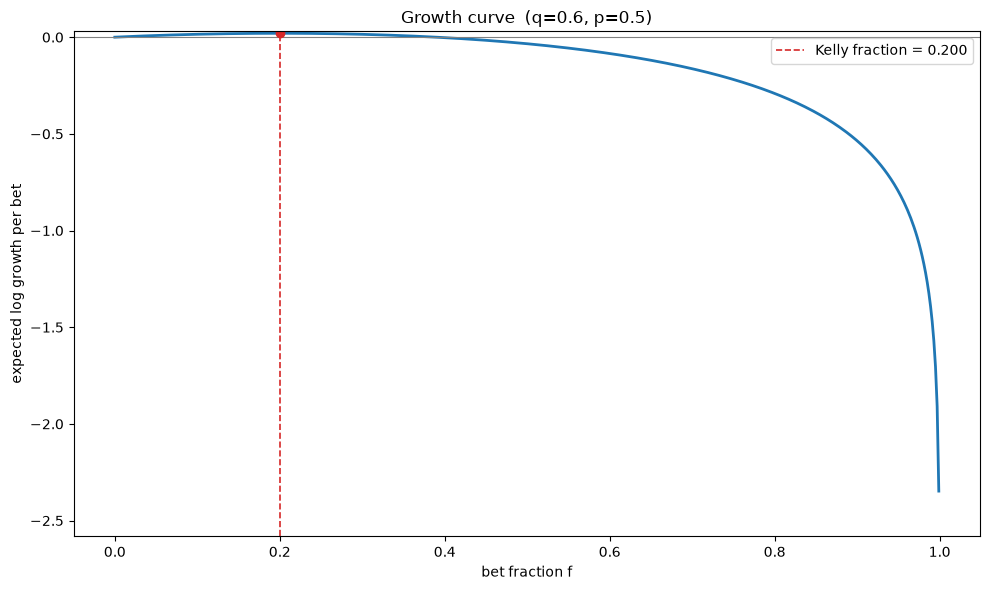

In [ ]:
# Plot expected growth

def plot_growth_curve(q, p, f_max=0.999):
    fs = np.linspace(0, f_max, 500)
    growth = [expected_log_growth(q, p, f) for f in fs]

    kelly_f = kelly_fraction(q, p)
    kelly_growth = expected_log_growth(q, p, kelly_f)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(fs, growth, color="C0", lw=2)
    ax.axhline(0, color="gray", lw=0.8)                       # zero reference
    ax.axvline(kelly_f, color="C3", ls="--", lw=1.2,
               label=f"Kelly fraction = {kelly_f:.3f}")
    ax.plot(kelly_f, kelly_growth, "o", color="C3")           # mark the peak

    ax.set_xlabel("bet fraction f")
    ax.set_ylabel("expected log growth per bet")
    ax.set_title(f"Growth curve  (q={q}, p={p})")
    ax.legend()

    # keep the y-axis readable — the curve dives to -inf near f=1, so clip the view
    finite = [g for g in growth if np.isfinite(g)]
    ax.set_ylim(min(finite) * 1.1 if min(finite) < 0 else -0.5,
                max(finite) * 1.5)

    plt.tight_layout()
    plt.show()

plot_growth_curve(0.6, 0.5)

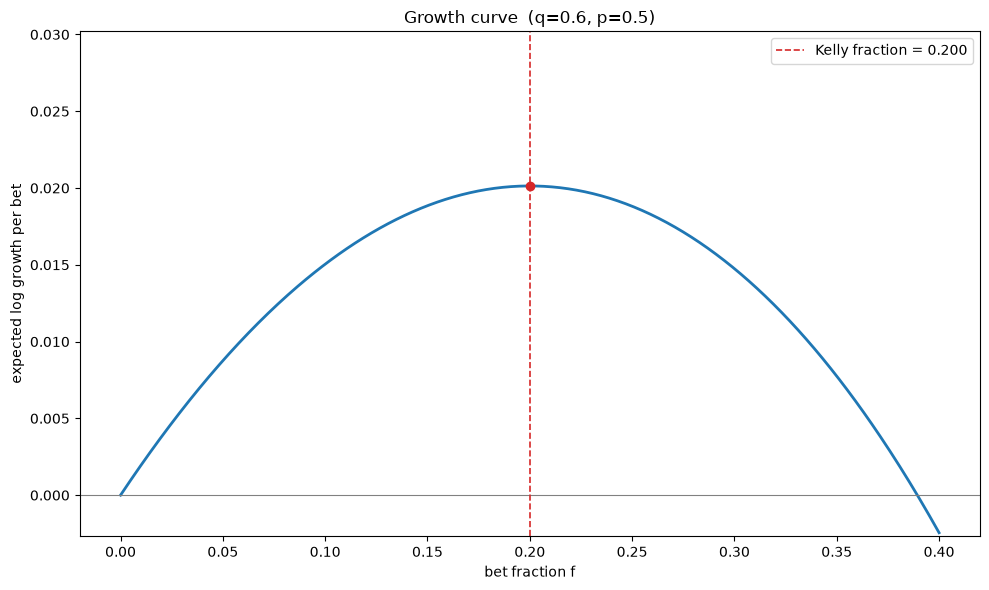

In [12]:
plot_growth_curve(0.6, 0.5, 0.4)